# Predicting hard-drive failures from SMART telemetry: analysis

A storage fleet replaces a few drives every day. If a drive's SMART telemetry warns of a failure early enough, the
data can be migrated and the drive swapped on a schedule instead of rebuilt after the fact. This notebook walks
through the results of `scripts/run_pipeline.py` on Backblaze Drive Stats (1 Oct 2025 - 28 Feb 2026, 151 daily
snapshots, 50.9 million drive-days):

| Part | Question | Validation |
|---|---|---|
| Data | Is the ETL right? | Q4 2025 drive counts, drive days, failures and AFR against Backblaze's published table |
| Reliability | How do failure rates vary by model and age? | exact Poisson CIs; Kaplan-Meier with delayed entry vs AFR |
| Prediction | Will a drive fail within 30 days? | drive-disjoint groups and a later test month; bootstrap over drives; Holm correction |
| Leakage | How much does a careless split overstate performance? | the same model under four split protocols |
| Alerting | Which threshold should trigger a swap? | threshold chosen on validation drives, applied to the test month, for six cost ratios |
| Explanation | What drives the predictions? | TreeSHAP (checked against the `shap` library) |

Everything below reads the tables in `reports/results/`. Run settings:

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RES, FIG = ROOT / 'reports' / 'results', ROOT / 'reports' / 'figures'
pd.set_option('display.precision', 4)
pd.set_option('display.max_colwidth', 70)
pd.set_option('display.width', 200)
meta = json.loads((RES / 'run_metadata.json').read_text())
{k: meta['settings'][k] for k in ['start', 'end', 'horizon', 'train_start', 'train_end', 'test_start',
                                  'test_end', 'drive_rate', 'group_cuts', 'trials', 'main_cost_ratio']}

{'start': '2025-10-01',
 'end': '2026-02-28',
 'horizon': 30,
 'train_start': '2025-10-31',
 'train_end': '2025-11-30',
 'test_start': '2025-12-31',
 'test_end': '2026-01-30',
 'drive_rate': 0.15,
 'group_cuts': [55, 70],
 'trials': [['LightGBM', 25], ['XGBoost', 15], ['CatBoost', 8]],
 'main_cost_ratio': 10}

## 1. Data and the published-table check

The pipeline downloads only the needed daily CSVs out of Backblaze's quarterly zip archives with HTTP range requests
(2.0 GB compressed), checks each file's CRC-32, and keeps 28 columns per day as Parquet. There are no duplicate
(serial, date) rows and no missing serial numbers. Spark (local mode, two cores) then aggregates daily counts,
builds one record per drive and computes the features.

The recomputed Q4 2025 numbers match Backblaze's published quarterly table for all 33 drive models: drive counts
(distinct drives seen in the quarter), drive days, failures and AFR are identical, 30,534,025 drive days and 943
failures in total (AFR 1.13%). Recomputed mean ages agree within a few months except for ST8000DM002, whose
power-on hours (SMART 9) wrap around at 65,536 hours; that model is left out of the age analyses.

In [2]:
pd.read_csv(RES / 'data_quality.csv').T

,0
days,151
first_day,2025-10-01
last_day,2026-02-28
rows,50888711
failures_all_models,1571
duplicate_serial_days,0
missing_serials,0
days_crc32_verified,151
compressed_gb,2.013
modelled_models,33


In [3]:
pd.read_csv(RES / 'afr_crosscheck_totals.csv')

,quantity,published,recomputed
0,models,3.3000e+01,3.3000e+01
1,drive_count,3.3719e+05,3.3719e+05
2,drive_days,3.0534e+07,3.0534e+07
3,failures,9.4300e+02,9.4300e+02
4,afr_pct,1.1300e+00,1.1300e+00


In [4]:
chk = pd.read_csv(RES / 'afr_crosscheck_q4_2025.csv')
print('models with identical drive count, drive days and failures:', int(chk.exact_match.sum()), 'of', len(chk))
chk[['model', 'drive_count_published', 'drive_count_recomputed', 'drive_days_published', 'drive_days_recomputed',
     'failures_published', 'failures_recomputed', 'afr_pct_published', 'afr_pct_recomputed',
     'avg_age_months_published', 'avg_age_months_recomputed']]

models with identical drive count, drive days and failures: 33 of 33


,model,drive_count_published,drive_count_recomputed,drive_days_published,drive_days_recomputed,failures_published,failures_recomputed,afr_pct_published,afr_pct_recomputed,avg_age_months_published,avg_age_months_recomputed
0,HMS5C4040BLE640,187,187,17151,17151,1,1,2.13,2.13,103.3,105.7
1,HUH728080ALE600,1073,1073,95800,95800,27,27,10.29,10.29,90.4,91.6
2,HUH721212ALE600,2610,2610,239745,239745,4,4,0.61,0.61,72.5,73.4
3,HUH721212ALE604,13371,13371,1221499,1221499,85,85,2.54,2.54,53.5,54.0
4,HUH721212ALN604,9877,9877,900963,900963,76,76,3.08,3.08,78.0,78.3
5,ST8000DM002,8960,8960,818034,818034,38,38,1.70,1.70,109.9,7.5
6,ST8000NM000A,247,247,22700,22700,0,0,0.00,0.00,35.1,34.9
7,ST8000NM0055,13300,13300,1217828,1217828,56,56,1.68,1.68,98.6,98.4
8,ST10000NM0086,1000,1000,90651,90651,13,13,5.23,5.23,95.2,95.6
9,ST12000NM0007,993,993,90539,90539,9,9,3.63,3.63,72.9,73.0


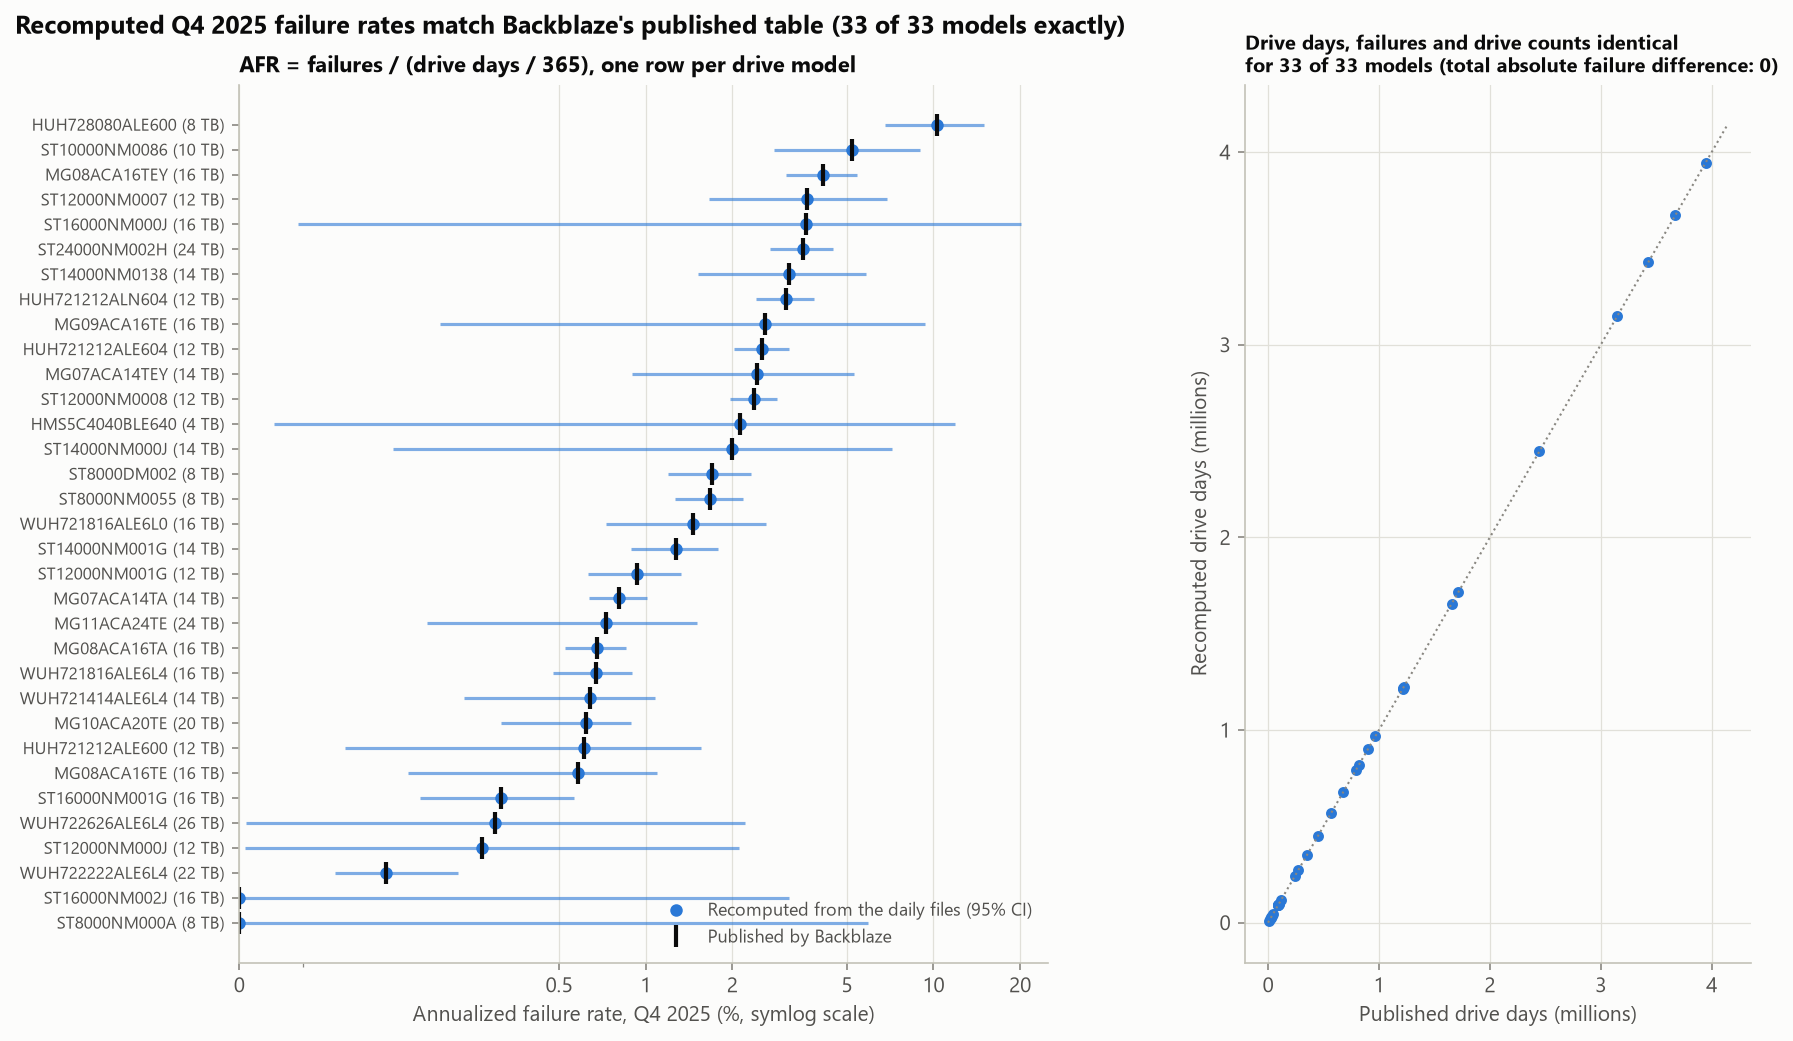

In [5]:
display(Image(FIG / '01_afr_crosscheck.png'))

## 2. Labels and splits

A drive-day is positive when the drive's recorded failure falls within the next 30 days (that day included). Drives
are split by a hash of the serial number into training (A, 55%), validation (B, 15%) and test (C, 30%) groups.
Models train on November drive-days of group A (features use October as warm-up history), are tuned on November
drive-days of group B, and are tested on January drive-days of group C. The test month starts 30 days after the
training month ends, so every training label was known before the first test day.

Healthy drives are subsampled (15% kept, weight 1/0.15) and every drive that fails in the label window is kept; the
weighted sample reproduces the exact number of drive-days within 0.6%. Rows whose 30-day window runs past a drive's
last report without a failure (drives retired or moved) are censored and left out.

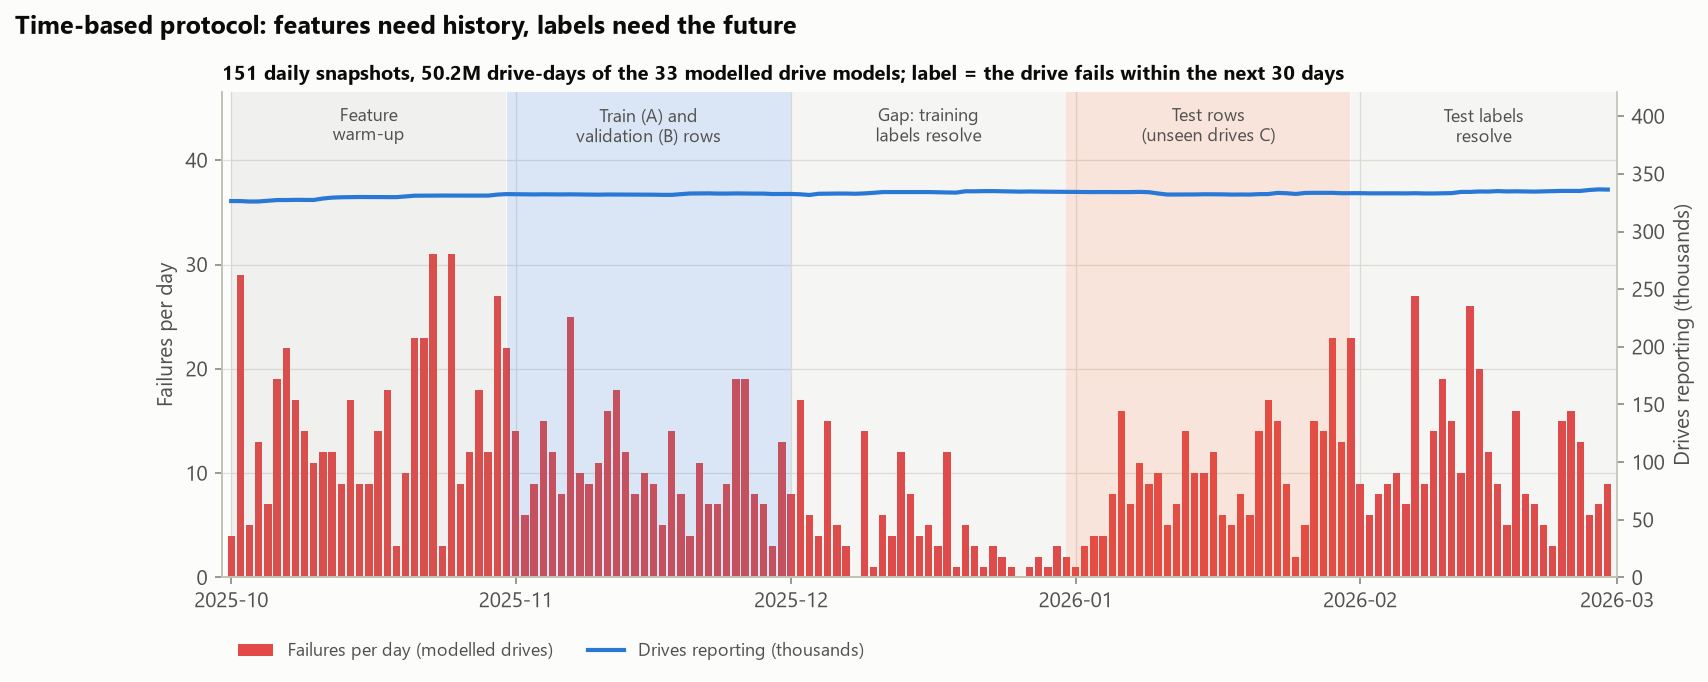

In [6]:
display(Image(FIG / '00_data_window.png'))

In [7]:
pd.read_csv(RES / 'label_stats.csv')

,period,group,rows,weighted_rows,positive_rows,censored_rows,drives,failing_drives,positive_rate_weighted
0,test,A,854165,5.6504e+06,5090,2574,27951,336,0.0009
1,test,B,229244,1.5184e+06,1247,633,7489,81,0.0008
2,test,C,468555,3.0993e+06,2898,1276,15320,188,0.0009
3,train,A,859902,5.6446e+06,4061,120,27975,281,0.0007
4,train,B,229952,1.5114e+06,1028,33,7472,73,0.0007
5,train,C,470659,3.0910e+06,2050,92,15306,140,0.0007


In [8]:
pd.read_csv(RES / 'sampling_check.csv')

,period,exact_drive_days,weighted_sample_estimate,relative_error_pct,group,drives,kept,failing_in_window,share_of_drives
0,train,1.0305e+07,1.0247e+07,-0.5578,NaN,NaN,NaN,NaN,NaN
1,test,1.0328e+07,1.0268e+07,-0.5838,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,A,187735.0,28584.0,632.0,0.5498
3,NaN,NaN,NaN,NaN,B,51025.0,7666.0,157.0,0.1494
4,NaN,NaN,NaN,NaN,C,102681.0,15652.0,337.0,0.3007


## 3. Failure rates, age and Kaplan-Meier survival

AFR = failures / (drive days / 365). Over the five months the 33 models average 1.14%. In Q4 2025 the rate ranges
from 0.23% for the largest model (WUH722222ALE6L4, 22 TB) to 10.3% for HUH728080ALE600 (8 TB, about 1,000 drives
aged 7.5 years); two small models had no failures. By power-on age, the failure rate is about 1.0% in
the first year, 0.5% in years 1-3, 1.2-1.4% in years 4-6 and 2.8-4.2% in years 6-8; the oldest bin (8-9 years) is
again lower (1.7%), as expected when only the sturdiest cohorts are still in service.

The Kaplan-Meier curves use delayed entry: each drive joins the risk set at the age it had on 1 October, so five
months of observation cover ages from 0 to 7 years. The one-year failure probability read off the KM curve at each
model's median age agrees with the model's AFR over the window (for example ST12000NM0008: 2.2% vs 2.5%;
HUH721212ALE604: 2.8% vs 2.6%).

In [9]:
afr = pd.read_csv(RES / 'afr_by_model.csv')
afr[afr.period == 'Oct 2025-Feb 2026'].sort_values('drive_days', ascending=False)[
    ['model', 'manufacturer', 'drive_count', 'drive_days', 'failures', 'afr_pct', 'afr_ci_low', 'afr_ci_high']].head(15)

,model,manufacturer,drive_count,drive_days,failures,afr_pct,afr_ci_low,afr_ci_high
97,WUH722222ALE6L4,WDC,44461,6560204,52,0.2893,0.2161,0.3794
73,MG08ACA16TA,Toshiba,40115,5991371,131,0.7981,0.6673,0.9470
71,MG07ACA14TA,Toshiba,37345,5621444,134,0.8701,0.7290,1.0305
88,ST16000NM001G,Seagate,34666,5175670,69,0.4866,0.3786,0.6158
96,WUH721816ALE6L4,WDC,26824,4020189,80,0.7263,0.5759,0.9040
81,ST12000NM0008,Seagate,18771,2808197,195,2.5345,2.1913,2.9163
77,MG10ACA20TE,Toshiba,19254,2720620,51,0.6842,0.5094,0.8996
68,HUH721212ALE604,HGST,13372,1998301,141,2.5754,2.1679,3.0373
83,ST12000NM001G,Seagate,13248,1992411,56,1.0259,0.7749,1.3322
93,ST8000NM0055,Seagate,13300,1989911,74,1.3573,1.0658,1.7040


In [10]:
pd.read_csv(RES / 'km_summary.csv')

,model,manufacturer,drives,failures,entry_age_min,entry_age_median,entry_age_max,km_1yr_failure_pct_from_median_age,afr_pct_window,afr_ci_low,afr_ci_high
0,WUH722222ALE6L4,WDC,44440,52,0.0000,0.9179,2.5368,0.2130,0.2893,0.2161,0.3794
1,MG08ACA16TA,Toshiba,40115,131,0.0000,2.1149,5.6651,0.8130,0.7981,0.6673,0.9470
2,MG07ACA14TA,Toshiba,37345,134,1.0179,4.8838,7.0389,0.6034,0.8701,0.7290,1.0305
3,ST16000NM001G,Seagate,34650,65,0.0000,3.4402,5.9830,0.3829,0.4866,0.3786,0.6158
4,WUH721816ALE6L4,WDC,26823,80,0.0000,2.6386,3.6359,1.1779,0.7263,0.5759,0.9040
5,MG10ACA20TE,Toshiba,19254,51,0.0000,0.5152,2.2944,0.6461,0.6842,0.5094,0.8996
6,ST12000NM0008,Seagate,18766,191,0.0241,5.4822,5.9811,2.2135,2.5345,2.1913,2.9163
7,HUH721212ALE604,HGST,13371,140,0.0000,4.4577,5.2821,2.7711,2.5754,2.1679,3.0373


In [11]:
ab = pd.read_csv(RES / 'afr_by_age.csv')
ab[ab.drive_years >= 500].pivot_table(index='age_from', columns='group', values='afr_pct').round(2)

group,HGST,Seagate,Toshiba,WDC,all
age_from,,,,,
0,NaN,2.92,0.56,0.49,1.00
1,NaN,0.66,0.83,0.23,0.49
2,NaN,0.33,0.75,0.37,0.54
3,NaN,0.14,1.37,1.39,1.03
4,2.63,1.00,0.92,1.08,1.24
5,1.81,1.89,0.81,0.37,1.37
6,2.86,2.63,3.33,NaN,2.83
7,4.71,NaN,NaN,NaN,4.23
8,NaN,1.81,NaN,NaN,1.72


In [12]:
pd.read_csv(RES / 'survival_data_check.csv')

,drives,models_excluded_age_mismatch,drives_excluded_age_mismatch,valid_power_on_hours,dropped_invalid_hours,dropped_failures
0,341441,ST8000DM002,8960,330317,2164,37


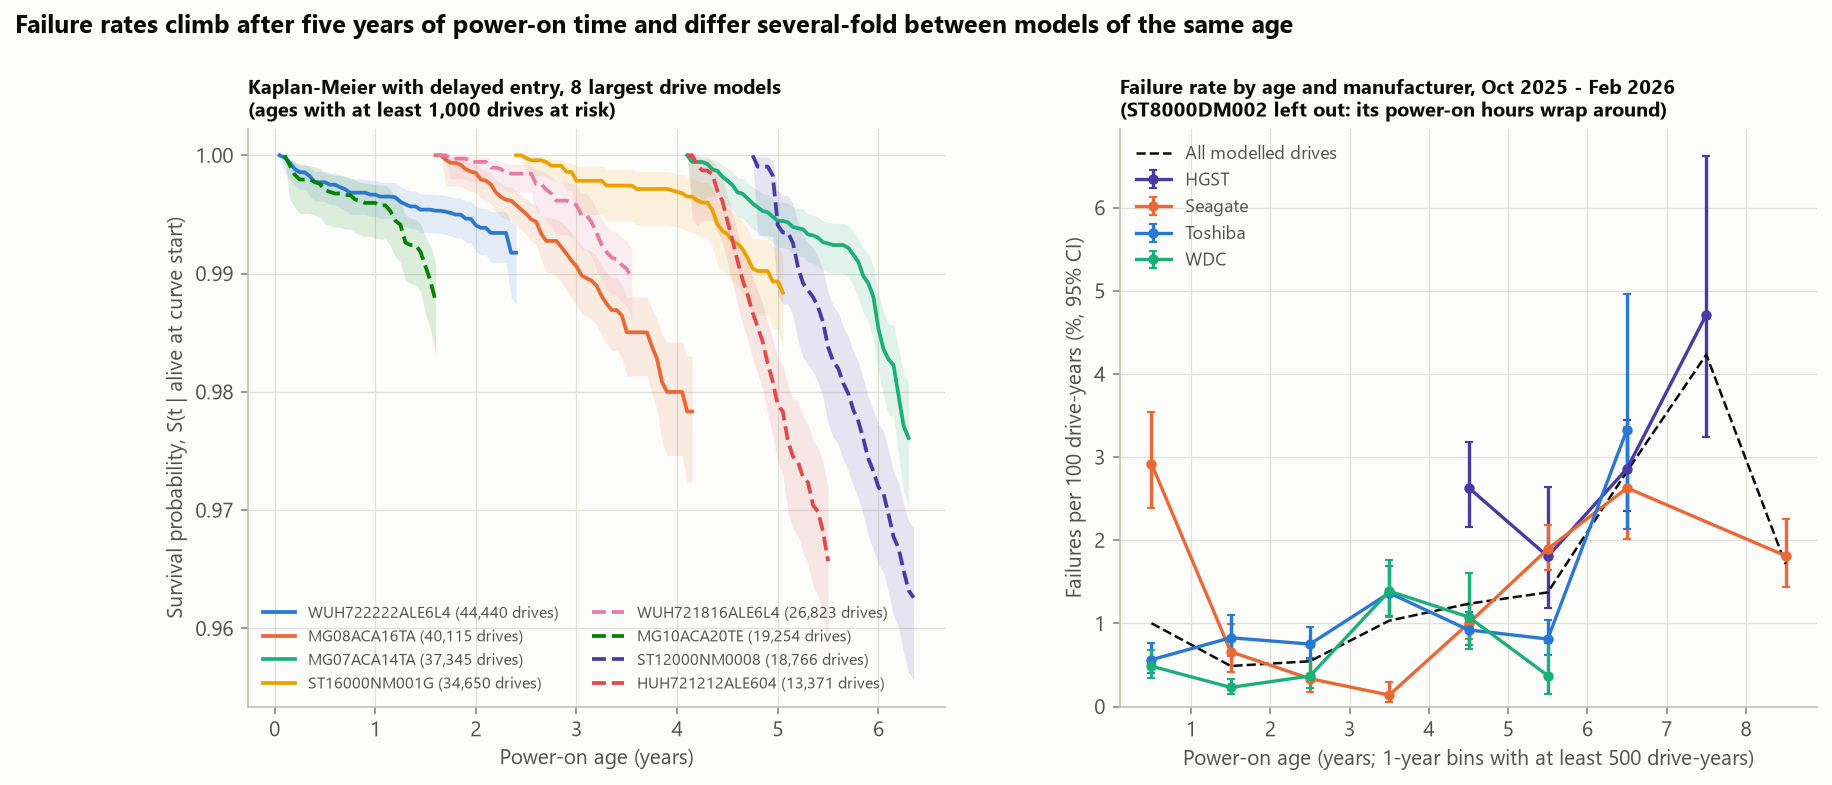

In [13]:
display(Image(FIG / '02_survival.png'))

## 4. Models on unseen drives in a later month

Five scorers are compared on the 467,279 January drive-days of group C (188 failing drives): the sum of the five
critical SMART counters (5, 187, 188, 197, 198) as a rule baseline, logistic regression, and LightGBM, XGBoost and
CatBoost tuned with Optuna (25, 15 and 8 trials) on group B's weighted average precision. CIs come from 400
bootstrap resamples of drives; paired differences against logistic regression are Holm-corrected over 16 tests.

On validation, LightGBM led clearly (AP 0.190 vs 0.059 for logistic regression). On the test month the ranking does
not hold: logistic regression reaches AP 0.145, XGBoost 0.131 and LightGBM 0.117, and the differences are not
significant. CatBoost (early-stopped after 12 rounds) is significantly worse (0.066). Every learned model is about
ten times better than the SMART rule (0.012). With 73 failing validation drives and 188 failing test drives, model
selection on one month is noisy; the validation CIs are as wide as the test CIs.

In [14]:
res = pd.read_csv(RES / 'model_results.csv')
res[['model', 'val_ap', 'val_ap_ci_low', 'val_ap_ci_high', 'ap', 'ap_ci_low', 'ap_ci_high', 'roc_auc',
     'recall_at_fpr_0.1pct', 'recall_at_fpr_1pct']]

,model,val_ap,val_ap_ci_low,val_ap_ci_high,ap,ap_ci_low,ap_ci_high,roc_auc,recall_at_fpr_0.1pct,recall_at_fpr_1pct
0,SMART rule (critical-counter sum),0.0104,0.0049,0.0200,0.0121,0.0079,0.0207,0.8145,0.0207,0.1425
1,Logistic regression,0.0589,0.0273,0.1162,0.1453,0.0888,0.2392,0.8913,0.2567,0.5345
2,LightGBM,0.1899,0.0990,0.2811,0.1165,0.0760,0.1688,0.8463,0.2257,0.4720
3,XGBoost,0.1612,0.0802,0.2484,0.1306,0.0841,0.1885,0.8750,0.2112,0.4693
4,CatBoost,0.1352,0.0716,0.2259,0.0664,0.0460,0.1076,0.8559,0.1501,0.5528


In [15]:
pd.read_csv(RES / 'model_significance.csv')[['model', 'metric', 'diff', 'diff_ci_low', 'diff_ci_high', 'p_value', 'p_holm']]

,model,metric,diff,diff_ci_low,diff_ci_high,p_value,p_holm
0,SMART rule (critical-counter sum),ap,-0.1332,-0.2230,-0.0783,0.000,0.000
1,SMART rule (critical-counter sum),roc_auc,-0.0768,-0.1095,-0.0439,0.000,0.000
2,SMART rule (critical-counter sum),recall_at_fpr_0.1pct,-0.2360,-0.3099,-0.1708,0.000,0.000
3,SMART rule (critical-counter sum),recall_at_fpr_1pct,-0.3920,-0.4696,-0.3041,0.000,0.000
4,LightGBM,ap,-0.0288,-0.1023,0.0202,0.240,0.960
5,LightGBM,roc_auc,-0.0450,-0.0715,-0.0187,0.000,0.000
6,LightGBM,recall_at_fpr_0.1pct,-0.0311,-0.1095,0.0289,0.275,0.960
7,LightGBM,recall_at_fpr_1pct,-0.0625,-0.1151,-0.0034,0.045,0.315
8,XGBoost,ap,-0.0146,-0.0958,0.0328,0.525,0.960
9,XGBoost,roc_auc,-0.0163,-0.0376,0.0049,0.160,0.960


In [16]:
pd.read_csv(RES / 'tuned_models.csv')[['model', 'trials', 'val_ap', 'best_iteration', 'tuning_seconds', 'params']]

,model,trials,val_ap,best_iteration,tuning_seconds,params
0,Logistic regression,3,0.0589,0,5.1699,"{""C"": 0.01}"
1,LightGBM,25,0.1899,118,60.0611,"{""objective"": ""binary"", ""metric"": ""average_precision"", ""num_thread..."
2,XGBoost,15,0.1612,109,24.6389,"{""objective"": ""binary:logistic"", ""eval_metric"": ""aucpr"", ""tree_met..."
3,CatBoost,8,0.1352,12,56.9694,"{""iterations"": 500, ""eval_metric"": ""PRAUC"", ""od_type"": ""Iter"", ""od..."


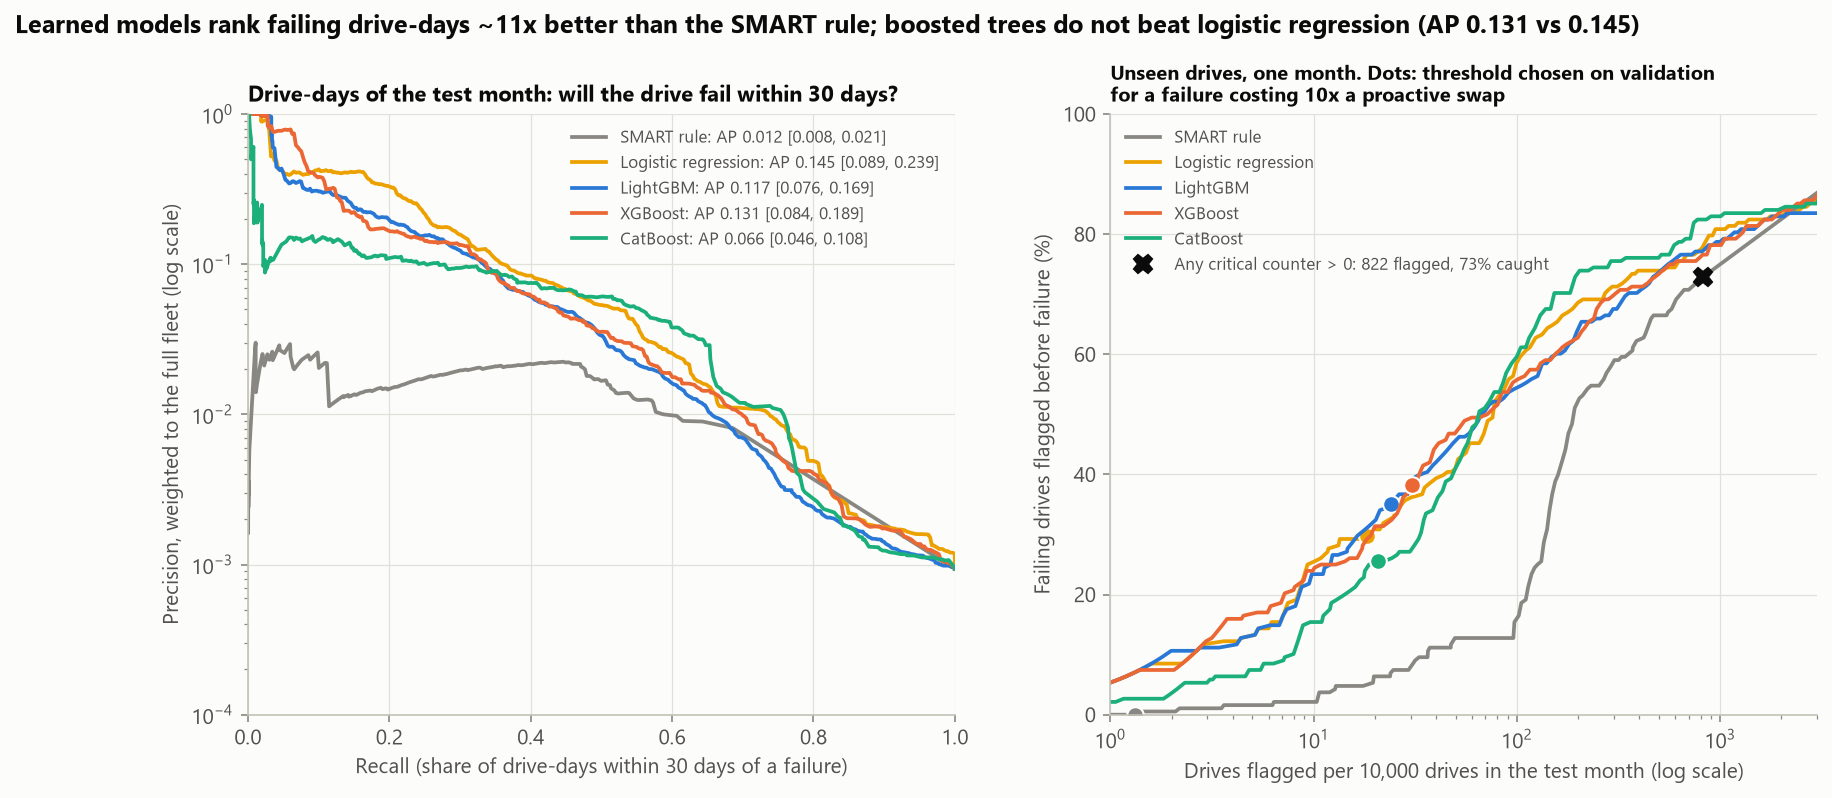

In [17]:
display(Image(FIG / '03_model_comparison.png'))

## 5. How much does the split matter?

The same LightGBM settings, refitted with a fixed number of rounds, under four protocols. A random split of
drive-days puts neighbouring days of the same failing drive on both sides, and the model only has to recognise
the drive: AP 0.477 and ROC AUC 0.998. Holding out whole drives drops AP to 0.053 in the same month; the same
drives one month later give 0.058; unseen drives in the later month 0.123. The random split overstates AP four- to
ninefold. (The later month has more failures per drive-day, which raises AP, so the last three protocols should not
be ranked against each other.)

In [18]:
pd.read_csv(RES / 'split_protocols.csv')[['protocol', 'train_rows', 'test_rows', 'test_failing_drives', 'ap',
    'ap_ci_low', 'ap_ci_high', 'roc_auc', 'recall_at_fpr_1pct']]

,protocol,train_rows,test_rows,test_failing_drives,ap,ap_ci_low,ap_ci_high,roc_auc,recall_at_fpr_1pct
0,Random row split (same month),106556,58129,390,0.4774,0.3748,0.5879,0.9979,0.9903
1,Drive-grouped split (same month),106257,470567,140,0.0535,0.0344,0.0899,0.8714,0.4683
2,"Same drives, later month",106257,851591,336,0.0579,0.0380,0.1108,0.8162,0.3835
3,Drive-grouped + later month (deployment),106257,467279,188,0.1226,0.0690,0.1884,0.8395,0.4593


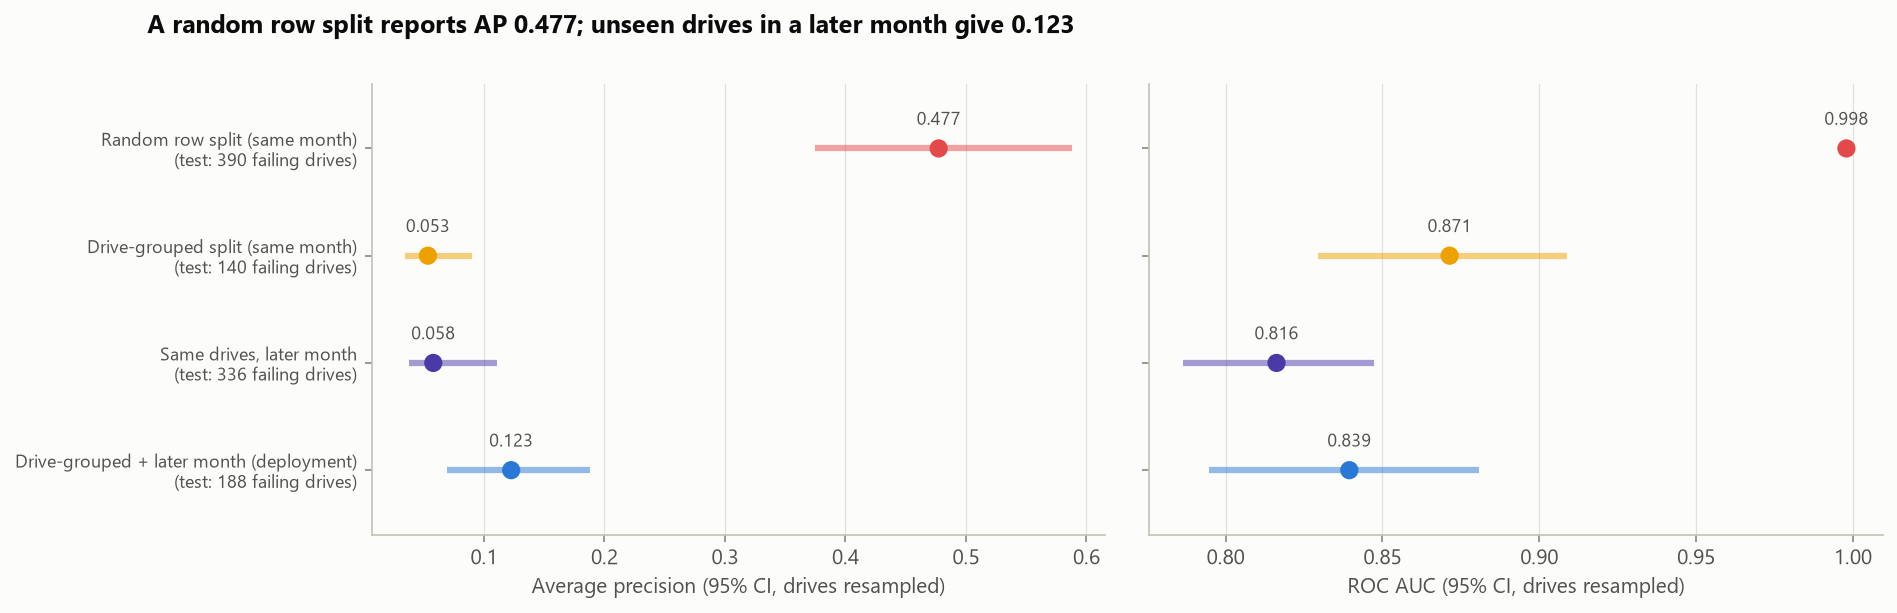

In [19]:
display(Image(FIG / '04_split_protocols.png'))

## 6. A cost-based alert threshold

A drive is flagged when its daily score crosses the threshold at least once during the month. A proactive swap costs
one unit and an unpredicted failure costs k units, so the net saving against doing nothing is
(k - 1) x failures caught - false alarms. The threshold maximising the saving on validation drives (November) is
applied to the test drives (January).

At k = 10, LightGBM flags 24 drives per 10,000 per month, catches 35% of failing drives at 27% precision, and saves
41.7 swap units per 10,000 drives (95% CI 27-58), 22% of the cost of all failures; the best threshold in hindsight
would have saved 43.6. The rule "any critical counter above zero" catches 73% of failing drives but flags 822
drives per 10,000 (precision 1.7%) and loses money at every cost ratio up to 50.

In [20]:
cost = pd.read_csv(RES / 'cost_by_ratio.csv')
cost[cost.cost_ratio == meta['settings']['main_cost_ratio']][['model', 'threshold', 'test_flagged_per_10k',
    'test_recall', 'test_precision', 'test_net_saving_per_10k', 'test_saving_ci_low', 'test_saving_ci_high',
    'test_saving_share', 'oracle_test_net_saving_per_10k']]

,model,threshold,test_flagged_per_10k,test_recall,test_precision,test_net_saving_per_10k,test_saving_ci_low,test_saving_ci_high,test_saving_share,oracle_test_net_saving_per_10k
3,SMART rule (critical-counter sum),9.3718e+11,1.3281,0.0000,0.0000,-1.3281,-3.3350,0.0000,-0.0071,0.0000
9,Logistic regression,9.0181e-01,18.2951,0.2979,0.3049,37.4868,23.6012,51.9330,0.2002,40.6743
15,LightGBM,9.6554e-01,24.0393,0.3511,0.2735,41.7036,27.2413,58.1748,0.2227,43.5630
21,XGBoost,6.8501e-01,30.6136,0.3830,0.2343,41.1059,24.3761,58.2437,0.2195,43.6626
27,CatBoost,7.0269e-01,20.8186,0.2553,0.2297,26.9945,13.6802,41.2564,0.1441,29.3519


In [21]:
cost.pivot_table(index='cost_ratio', columns='model', values='test_saving_share').round(3)

model,CatBoost,LightGBM,Logistic regression,SMART rule (critical-counter sum),XGBoost
cost_ratio,,,,,
2,-0.054,0.008,0.003,-0.035,0.029
3,-0.011,0.040,0.004,-0.024,0.076
5,0.044,0.094,0.102,-0.014,0.091
10,0.144,0.223,0.200,-0.007,0.220
20,0.285,0.312,0.317,-0.004,0.301
50,0.494,0.439,0.485,0.210,0.427


In [22]:
pd.read_csv(RES / 'fixed_rule.csv')

,model,cost_ratio,test_net_saving_per_10k,test_recall,test_precision,test_flagged_per_10k
0,SMART rule: any critical counter > 0,2,-794.8256,0.7287,0.0166,822.1188
1,SMART rule: any critical counter > 0,3,-781.1789,0.7287,0.0166,822.1188
2,SMART rule: any critical counter > 0,5,-753.8856,0.7287,0.0166,822.1188
3,SMART rule: any critical counter > 0,10,-685.6524,0.7287,0.0166,822.1188
4,SMART rule: any critical counter > 0,20,-549.1860,0.7287,0.0166,822.1188
5,SMART rule: any critical counter > 0,50,-139.7868,0.7287,0.0166,822.1188


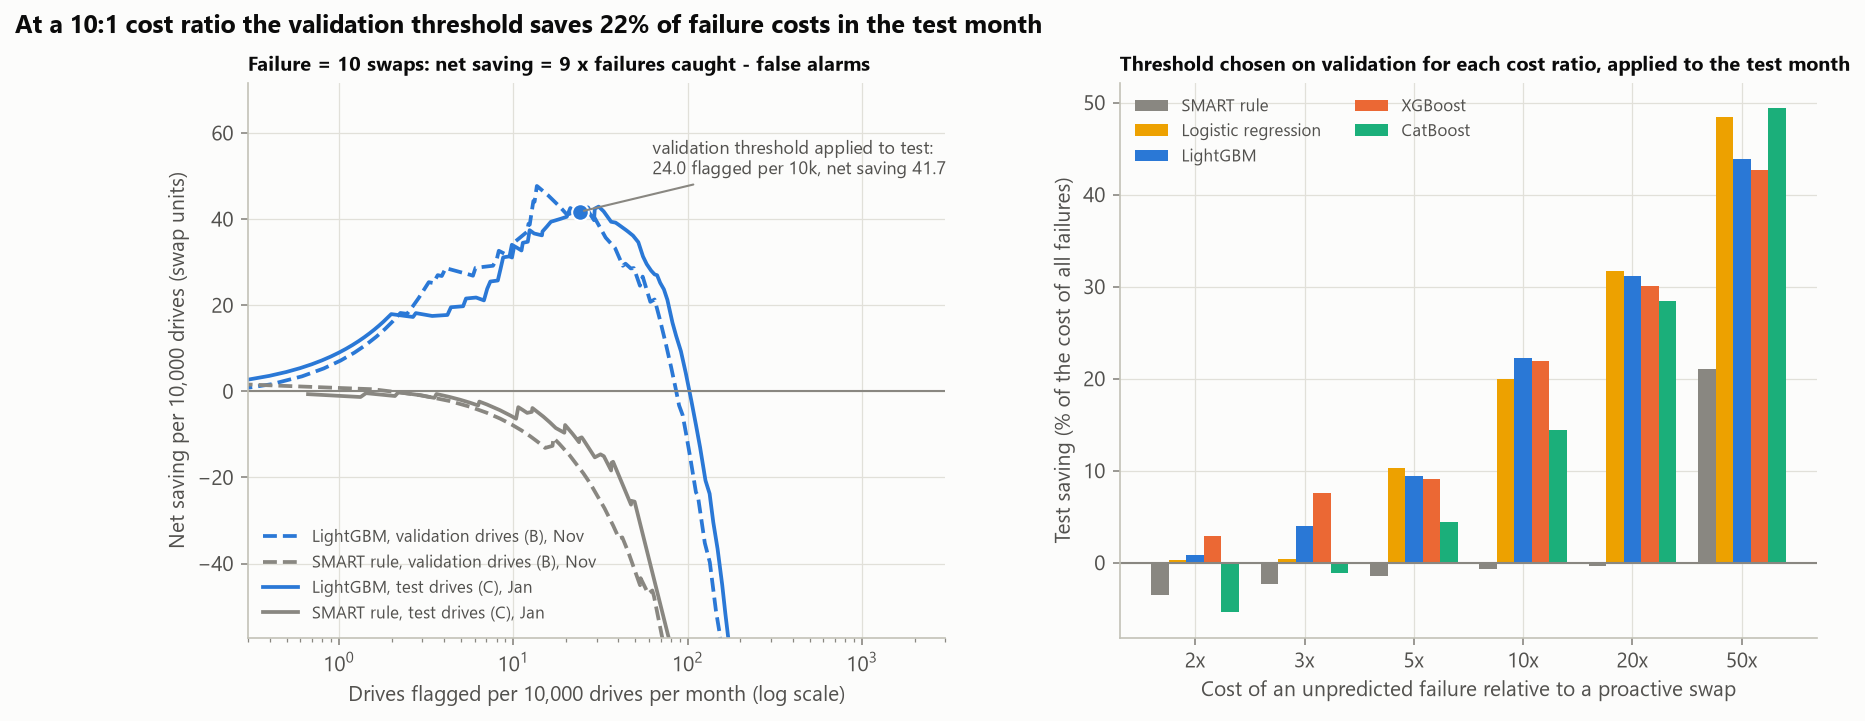

In [23]:
display(Image(FIG / '05_cost_threshold.png'))

## 7. Lead time and silent failures

At the k = 10 threshold LightGBM alerts 66 of 188 failing test drives; the median lead time is 16.5 days, but 15
alerts come on the last day or the day before the failure. 51 failing drives (27%) never show a critical counter
above zero during the month; the models catch 0-16% of those, against 35-47% of the drives that do show a signal.

In [24]:
lt = pd.read_csv(RES / 'lead_times.csv')
lt.groupby('model').agg(failing=('caught', 'size'), caught=('caught', 'sum'), median_lead_days=('lead_days', 'median'))

,failing,caught,median_lead_days
model,,,
CatBoost,188,48,21.5
LightGBM,188,66,16.5
Logistic regression,188,56,23.0
SMART rule (critical-counter sum),188,0,NaN
XGBoost,188,72,18.5


In [25]:
fs = pd.read_csv(RES / 'failure_signals.csv')
fs.pivot_table(index=['by', 'level'], columns='model', values='recall').round(3)

model                 CatBoost  LightGBM  Logistic regression  SMART rule (critical-counter sum)  XGBoost
by           level                                                                                       
crit_any     False       0.000     0.157                0.078                                0.0    0.157
             True        0.350     0.423                0.380                                0.0    0.467
manufacturer HGST        0.458     0.333                0.458                                0.0    0.417
             Seagate     0.346     0.494                0.444                                0.0    0.531
             Toshiba     0.170     0.302                0.113                                0.0    0.283
             WDC         0.000     0.067                0.100                                0.0    0.133

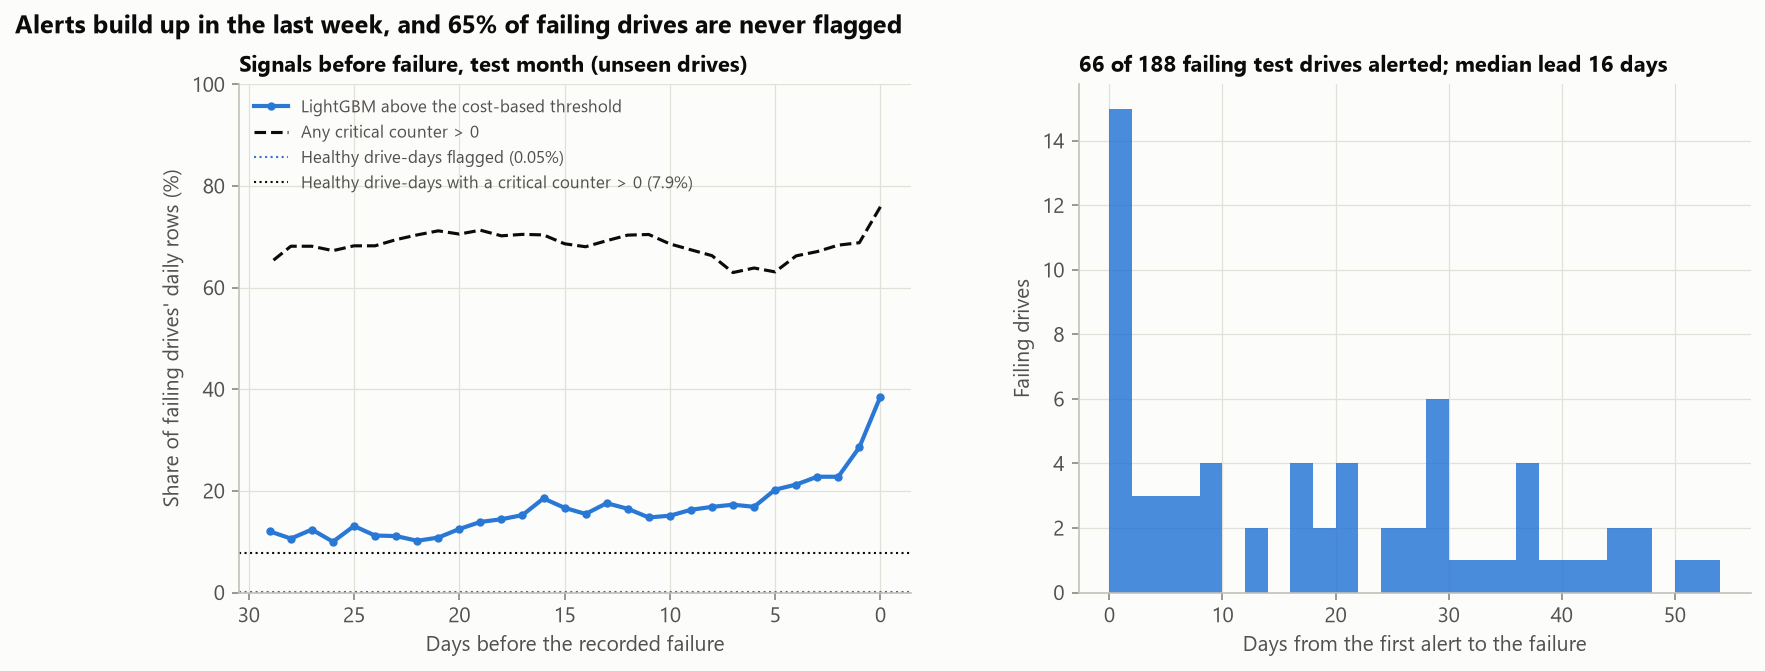

In [26]:
display(Image(FIG / '07_lead_time.png'))

## 8. What the model uses

TreeSHAP values from LightGBM's own implementation (identical to the `shap` library's on 200 rows; maximum absolute
difference 0). For drive-days before a failure, the largest contributions come from the number of days with an
increase in a critical counter over the last 30 days and the 30-day growth of pending (197) and reallocated (5)
sectors. For healthy drive-days the contributions come mostly from the drive model and usage (power cycles,
load/unload cycles, age, temperature), which set each drive's baseline risk.

In [27]:
print(meta['shap_check'])
pd.read_csv(RES / 'shap_importance.csv').head(15)

{'rows': 200, 'max_abs_diff_vs_shap_library': 0.0}


,feature,mean_abs_shap,mean_abs_shap_failing,mean_abs_shap_healthy,model
0,model_code,0.6483,0.6887,0.6078,LightGBM
1,crit_inc_days_30,0.6104,1.1164,0.1045,LightGBM
2,smart_12,0.4685,0.4566,0.4805,LightGBM
3,smart_193,0.4263,0.3915,0.4610,LightGBM
4,smart_197_d30,0.4138,0.7734,0.0541,LightGBM
5,age_days,0.3888,0.3609,0.4168,LightGBM
6,smart_192,0.3519,0.3109,0.3929,LightGBM
7,smart_5_d30,0.3489,0.6321,0.0657,LightGBM
8,temp_mean_7,0.3127,0.2606,0.3649,LightGBM
9,smart_198,0.3020,0.5051,0.0988,LightGBM


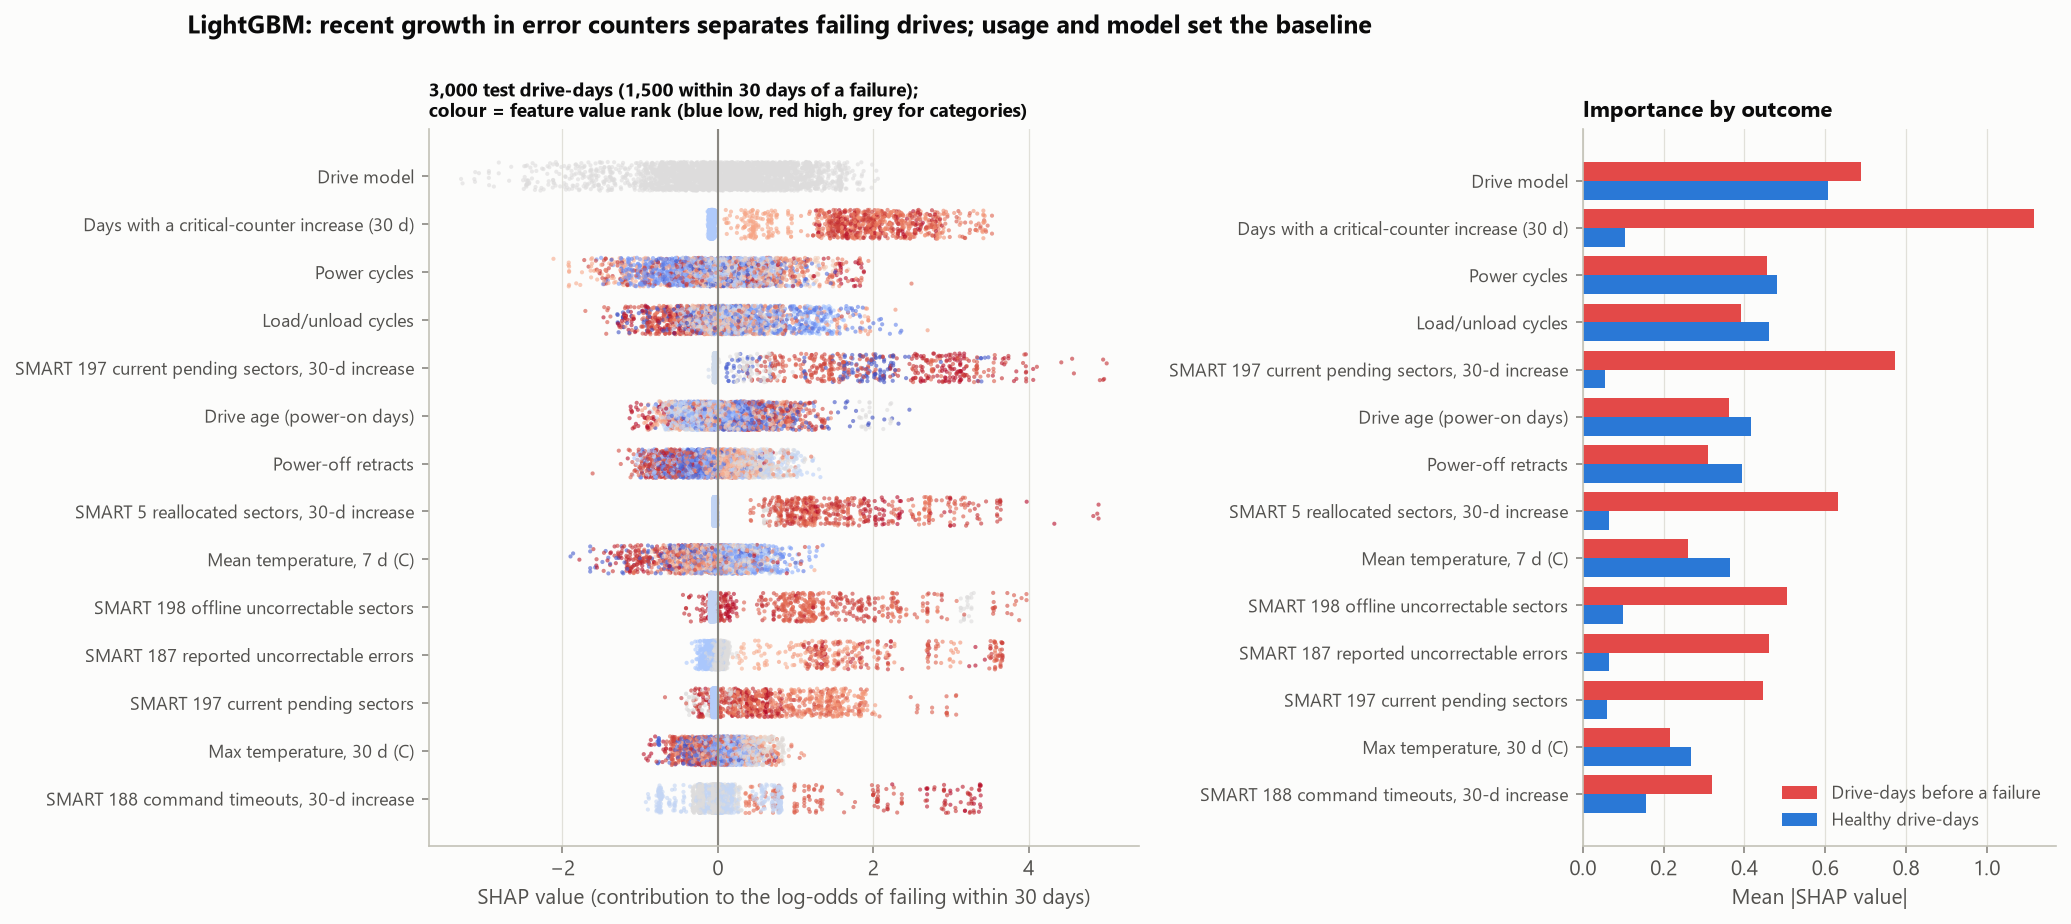

In [28]:
display(Image(FIG / '06_shap.png'))

## 9. Limitations

- Five months of data (2.0 GB download budget): one training month and one test month, 494 and 605 failing drives in
  the two label windows, 188 failing drives in the test group. Results for one month are noisy, and model rankings
  changed between validation and test.
- Backblaze records a failure when a drive is removed after failing; some removals are preventive, and drives that
  leave without a failure record are treated as censored.
- Features are daily SMART raw values; vendor-specific encodings (e.g. SMART 188 on Seagate drives) are used as-is.
- The cost model is a simple two-cost abstraction; real costs depend on redundancy, rebuild time and staffing.